In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [147]:

def coordinate2indices(xyz_position, reference_positions, h_spacing):
    #position finding (x, y, z, ...) to (i, j, k, ...)

    index = np.abs(xyz_position - reference_positions)/h_spacing # / = numpy element-wise division
    return np.array([int(a) for a  in index])  


def LocalGradient(function, index_position, h_spacing):

    dimension = np.shape(function)
    n = len(dimension)

    local_derivative = np.zeros(n)
    
    if n == 1:
        index_upgrade = 1
    else:
        index_upgrade = np.append(1, np.zeros(n - 1)) #will add +/-1 to corresponding index position

    position = function[*index_position]

    for b, a in enumerate(index_position):

        h = h_spacing[b]

        if a > 0 and a < dimension[b]:  
            local_derivative[b] = (function[*(index_position + index_upgrade)] - function[*(index_position - index_upgrade)])/(2*h)
            
        elif a == 0:
            local_derivative[b] = ( function[*(index_position + index_upgrade)] - position )/h

        elif a == dimension[b]: 
            local_derivative[b] = ( position - function[*(index_position - index_upgrade)] )/h

        np.roll(index_upgrade, 1) # switches to upgrade other axis
  
    return local_derivative


def GradientDescent(function, initial_position, boundary, h_spacing, errorMax ):

    position = initial_position
    index_position = coordinate2indices(position, boundary, h_spacing)
    gradient_function = LocalGradient(function, index_position, h_spacing)

    k = 0

    while np.linalg.norm(gradient_function) > errorMax:

        position += -h_spacing * gradient_function

        index_position = coordinate2indices(position, boundary, h_spacing)
        gradient_function = LocalGradient(function, index_position, h_spacing)

        k += 1
        if k > 50: 
            break

    return position

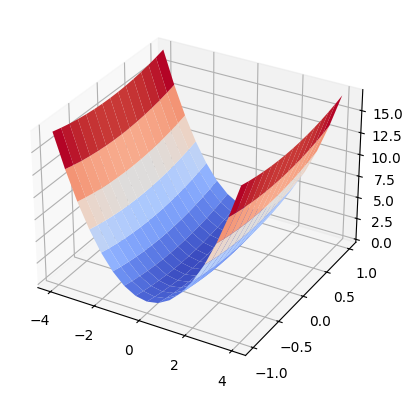

In [128]:
lim_x, lim_y = np.linspace(-4, 4, 17), np.linspace(-1, 1, 15)
X, Y = np.meshgrid(lim_x, lim_y)

function = X**2 + Y**2

fig, ax = plt.subplots(subplot_kw={"projection" : "3d"})
ax.plot_surface(X, Y, function, cmap = "coolwarm")

In [155]:
GradientDescent(function, np.array([-1.527, 1.23]), np.array([-4, -1]), np.array([8/16, 2/14]), 1e-1)


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [157]:
coordinate2indices(np.array([-1.527, 1.23]), np.array([-4, -1]), np.array([8/16, 2/14]))

array([ 4, 15])